In [1]:
import kagglehub

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [2]:
import os

DATA_DIR = "/kaggle/input/chest-xray-pneumonia"

print("Dataset path:", DATA_DIR)
print("Main folders:", os.listdir(DATA_DIR))

for folder in os.listdir(DATA_DIR):
    folder_path = os.path.join(DATA_DIR, folder)

    if os.path.isdir(folder_path):
        print(f"\nFolder: {folder}")
        print("Subfolders:", os.listdir(folder_path)[:10])

Dataset path: /kaggle/input/chest-xray-pneumonia
Main folders: ['chest_xray']

Folder: chest_xray
Subfolders: ['chest_xray', '__MACOSX', 'val', 'test', 'train']


In [4]:
import os

DATA_DIR = "/kaggle/input/chest-xray-pneumonia/chest_xray"

print("Dataset folders:", os.listdir(DATA_DIR))

Dataset folders: ['chest_xray', '__MACOSX', 'val', 'test', 'train']


In [5]:
import os

splits = ["train", "val", "test"]
classes = ["NORMAL", "PNEUMONIA"]
extensions = (".jpg", ".jpeg", ".png")

for split in splits:
    print(f"\n{split.upper()}")

    for class_name in classes:
        folder = os.path.join(DATA_DIR, split, class_name)

        if os.path.isdir(folder):
            count = sum(
                1 for f in os.listdir(folder)
                if f.lower().endswith(extensions)
            )
            print(f"{class_name}: {count}")
        else:
            print(f"{class_name}: Folder not found")


TRAIN
NORMAL: 1341
PNEUMONIA: 3875

VAL
NORMAL: 8
PNEUMONIA: 8

TEST
NORMAL: 234
PNEUMONIA: 390


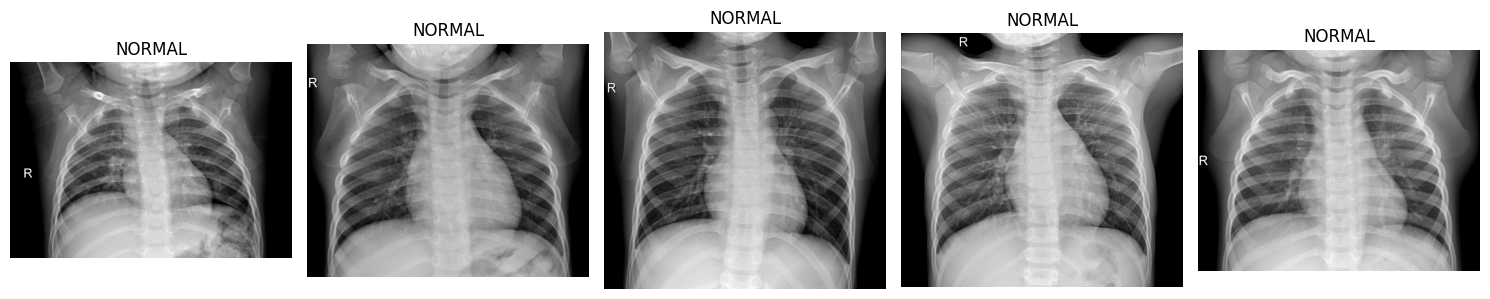

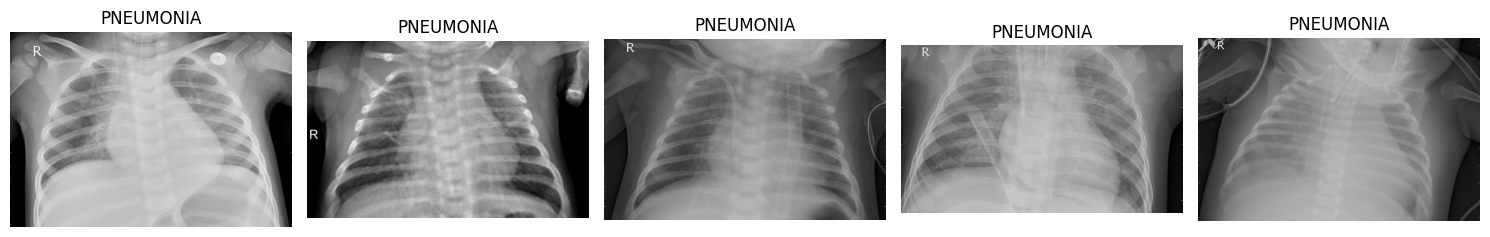

In [6]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = "/kaggle/input/chest-xray-pneumonia/chest_xray"

random.seed(42)

for class_name in ["NORMAL", "PNEUMONIA"]:

    folder = os.path.join(DATA_DIR, "train", class_name)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    samples = random.sample(image_files, 5)

    fig, axes = plt.subplots(1, 5, figsize=(15, 4))

    for ax, filename in zip(axes, samples):
        image_path = os.path.join(folder, filename)

        image = Image.open(image_path).convert("L")

        ax.imshow(image, cmap="gray")
        ax.set_title(class_name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [7]:
import os
import numpy as np
from PIL import Image


classes = ["NORMAL", "PNEUMONIA"]
splits = ["train", "val", "test"]
IMAGE_SIZE = (128, 128)

image_paths = []
labels = []

for split in splits:
    for class_name in classes:
        folder = os.path.join(DATA_DIR, split, class_name)

        for filename in os.listdir(folder):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                image_paths.append(os.path.join(folder, filename))

                labels.append(0 if class_name == "NORMAL" else 1)

labels = np.array(labels)

images = []

for path in image_paths:
    image = Image.open(path).convert("L")
    image = image.resize(IMAGE_SIZE)
    images.append(np.array(image, dtype=np.uint8))

images = np.array(images)

print("Total images:", len(images))
print("Image array shape:", images.shape)
print("Labels shape:", labels.shape)

Total images: 5856
Image array shape: (5856, 128, 128)
Labels shape: (5856,)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    images,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training images:", X_train.shape[0])
print("Validation images:", X_val.shape[0])
print("Testing images:", X_test.shape[0])

print("\nTraining shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training images: 4099
Validation images: 878
Testing images: 879

Training shape: (4099, 128, 128)
Validation shape: (878, 128, 128)
Testing shape: (879, 128, 128)


In [14]:
from skimage.feature import hog
from tqdm.auto import tqdm
import numpy as np

def extract_hog(images):
    features = []

    for image in tqdm(images, desc="Extracting HOG"):
        feature_vector = hog(
            image,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )
        features.append(feature_vector)

    return np.array(features, dtype=np.float32)


X_train_hog = extract_hog(X_train)
X_val_hog = extract_hog(X_val)
X_test_hog = extract_hog(X_test)

print("Training HOG:", X_train_hog.shape)
print("Validation HOG:", X_val_hog.shape)
print("Testing HOG:", X_test_hog.shape)

Extracting HOG:   0%|          | 0/4099 [00:00<?, ?it/s]

Extracting HOG:   0%|          | 0/878 [00:00<?, ?it/s]

Extracting HOG:   0%|          | 0/879 [00:00<?, ?it/s]

Training HOG: (4099, 8100)
Validation HOG: (878, 8100)
Testing HOG: (879, 8100)


In [15]:
from skimage.feature import local_binary_pattern
import numpy as np
from tqdm.auto import tqdm

RADIUS = 3
N_POINTS = 8 * RADIUS

def extract_lbp(images):
    features = []

    for image in tqdm(images, desc="Extracting LBP"):
        lbp_image = local_binary_pattern(
            image,
            N_POINTS,
            RADIUS,
            method="uniform"
        )

        histogram, _ = np.histogram(
            lbp_image.ravel(),
            bins=np.arange(0, N_POINTS + 3),
            range=(0, N_POINTS + 2),
            density=True
        )

        features.append(histogram)

    return np.array(features, dtype=np.float32)


X_train_lbp = extract_lbp(X_train)
X_val_lbp = extract_lbp(X_val)
X_test_lbp = extract_lbp(X_test)

print("Training LBP:", X_train_lbp.shape)
print("Validation LBP:", X_val_lbp.shape)
print("Testing LBP:", X_test_lbp.shape)

Extracting LBP:   0%|          | 0/4099 [00:00<?, ?it/s]

Extracting LBP:   0%|          | 0/878 [00:00<?, ?it/s]

Extracting LBP:   0%|          | 0/879 [00:00<?, ?it/s]

Training LBP: (4099, 26)
Validation LBP: (878, 26)
Testing LBP: (879, 26)


In [16]:
from skimage.feature import graycomatrix, graycoprops
import numpy as np
from tqdm.auto import tqdm

def extract_glcm(images):
    features = []

    for image in tqdm(images, desc="Extracting GLCM"):
        # Reduce grayscale levels from 256 to 32
        quantized = (image // 8).astype(np.uint8)

        glcm = graycomatrix(
            quantized,
            distances=[1],
            angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
            levels=32,
            symmetric=True,
            normed=True
        )

        feature_vector = []

        properties = [
            "contrast",
            "dissimilarity",
            "homogeneity",
            "energy",
            "correlation",
            "ASM"
        ]

        for prop in properties:
            values = graycoprops(glcm, prop)
            feature_vector.append(values.mean())
            feature_vector.append(values.std())

        features.append(feature_vector)

    return np.array(features, dtype=np.float32)


X_train_glcm = extract_glcm(X_train)
X_val_glcm = extract_glcm(X_val)
X_test_glcm = extract_glcm(X_test)

print("Training GLCM:", X_train_glcm.shape)
print("Validation GLCM:", X_val_glcm.shape)
print("Testing GLCM:", X_test_glcm.shape)

Extracting GLCM:   0%|          | 0/4099 [00:00<?, ?it/s]

Extracting GLCM:   0%|          | 0/878 [00:00<?, ?it/s]

Extracting GLCM:   0%|          | 0/879 [00:00<?, ?it/s]

Training GLCM: (4099, 12)
Validation GLCM: (878, 12)
Testing GLCM: (879, 12)


In [17]:
X_train_features = np.concatenate(
    [X_train_hog, X_train_lbp, X_train_glcm],
    axis=1
)

X_val_features = np.concatenate(
    [X_val_hog, X_val_lbp, X_val_glcm],
    axis=1
)

X_test_features = np.concatenate(
    [X_test_hog, X_test_lbp, X_test_glcm],
    axis=1
)

print("Combined training:", X_train_features.shape)
print("Combined validation:", X_val_features.shape)
print("Combined testing:", X_test_features.shape)

Combined training: (4099, 8138)
Combined validation: (878, 8138)
Combined testing: (879, 8138)


In [18]:
import numpy as np
import tensorflow as tf

X_train_cnn = X_train.astype("float32")[..., np.newaxis] / 255.0
X_val_cnn = X_val.astype("float32")[..., np.newaxis] / 255.0
X_test_cnn = X_test.astype("float32")[..., np.newaxis] / 255.0

print("Training shape:", X_train_cnn.shape)
print("Validation shape:", X_val_cnn.shape)
print("Testing shape:", X_test_cnn.shape)

Training shape: (4099, 128, 128, 1)
Validation shape: (878, 128, 128, 1)
Testing shape: (879, 128, 128, 1)


In [19]:
from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(128, 128, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,193 (12.60 MB)

 Trainable params: 3,304,193 (12.60 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
from sklearn.utils.class_weight import compute_class_weight

# Account for class imbalance in the training set
unique_classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=unique_classes,
    y=y_train
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(unique_classes, weights)
}

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = cnn_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=15,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 158s 1s/step - accuracy: 0.8146 - loss: 0.3765 - val_accuracy: 0.9180 - val_loss: 0.1972
Epoch 2/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 188s 1s/step - accuracy: 0.9275 - loss: 0.1936 - val_accuracy: 0.9408 - val_loss: 0.1549
Epoch 3/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.9400 - loss: 0.1594 - val_accuracy: 0.9294 - val_loss: 0.1953
Epoch 4/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 151s 1s/step - accuracy: 0.9414 - loss: 0.1458 - val_accuracy: 0.9362 - val_loss: 0.1734
Epoch 5/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 199s 1s/step - accuracy: 0.9524 - loss: 0.1259 - val_accuracy: 0.9351 - val_loss: 0.1851


In [21]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

TUNE_SIZE = min(1500, len(y_train))

X_tune, _, y_tune, _ = train_test_split(
    X_train_features,
    y_train,
    train_size=TUNE_SIZE,
    stratify=y_train,
    random_state=42
)

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])
param_grid = {
    "svm__C": [0.1, 1, 10],
    "svm__kernel": ["linear", "rbf"],
    "svm__class_weight": ["balanced"]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_tune, y_tune)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1-score:", grid_search.best_score_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'svm__C': 1, 'svm__class_weight': 'balanced', 'svm__kernel': 'rbf'}
Best cross-validation F1-score: 0.9617501220985388


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_prob_cnn = cnn_model.predict(
    X_test_cnn,
    batch_size=32,
    verbose=1
).ravel()

y_pred_cnn = (y_prob_cnn >= 0.5).astype(int)

print("CNN Evaluation Results")
print("----------------------")
print("Accuracy :", accuracy_score(y_test, y_pred_cnn))
print("Precision:", precision_score(y_test, y_pred_cnn, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_cnn, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred_cnn, zero_division=0))
print("AUROC    :", roc_auc_score(y_test, y_prob_cnn))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_cnn,
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

28/28 ━━━━━━━━━━━━━━━━━━━━ 8s 272ms/step
CNN Evaluation Results
----------------------
Accuracy : 0.9476678043230944
Precision: 0.9775280898876404
Recall   : 0.9500780031201248
F1-score : 0.9636075949367089
AUROC    : 0.9804271162443137

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.88      0.94      0.91       238
   PNEUMONIA       0.98      0.95      0.96       641

    accuracy                           0.95       879
   macro avg       0.93      0.95      0.94       879
weighted avg       0.95      0.95      0.95       879



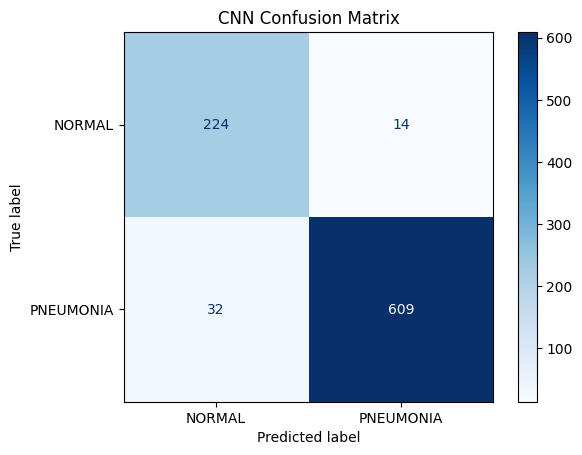

True Negatives (TN): 224
False Positives (FP): 14
False Negatives (FN): 32
True Positives (TP): 609


In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred_cnn,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("CNN Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

                    Accuracy  Precision  Recall  F1-score   AUROC
CNN                   0.9477     0.9775  0.9501    0.9636  0.9804
SVM (HOG+LBP+GLCM)    0.9636     0.9765  0.9735    0.9750  0.9865


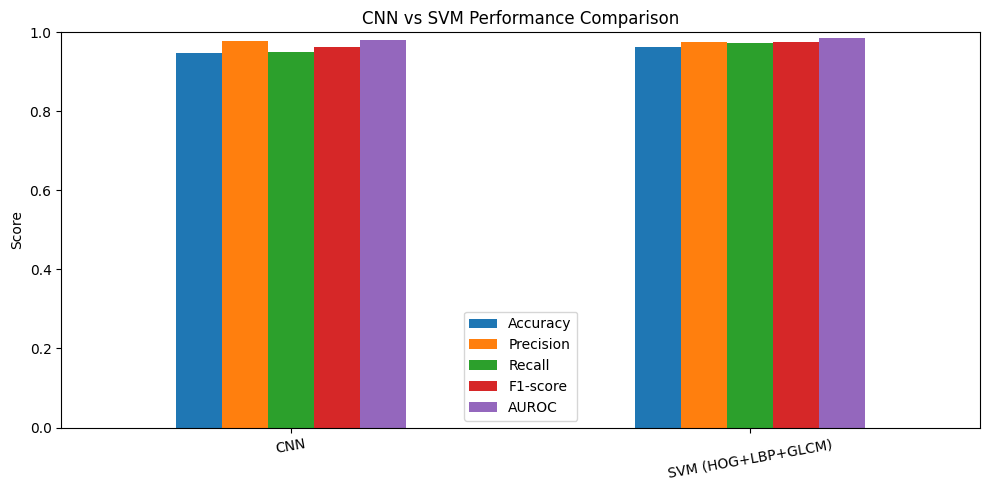


Best model by F1-score: SVM (HOG+LBP+GLCM)


In [24]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

best_svm = grid_search.best_estimator_
best_svm.fit(X_train_features, y_train)

y_pred_svm = best_svm.predict(X_test_features)
y_score_svm = best_svm.decision_function(X_test_features)

def evaluate_model(y_true, y_pred, y_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "AUROC": roc_auc_score(y_true, y_score)
    }

results = pd.DataFrame({
    "CNN": evaluate_model(
        y_test, y_pred_cnn, y_prob_cnn
    ),
    "SVM (HOG+LBP+GLCM)": evaluate_model(
        y_test, y_pred_svm, y_score_svm
    )
}).T

print(results.round(4))

results.plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
plt.title("CNN vs SVM Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

print(
    "\nBest model by F1-score:",
    results["F1-score"].idxmax()
)